### This notebook helps to understand how a shape of mata-atoms looks like, and what data collects for library.
**Note:** almost all variables are located in conf.py.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import meep as mp
import conf

### At first we describe PML layer, cell, substrate, meta-atom (geometry), and source
**Note:** That is very important to know where axes XYZ are.
1. X ----> this is direction along width of display
2. Y ^ this is direction along height of display: from down to top
3. Z X this direction is perpendicular to the screen

**Note:** For meta-atom we use another names for variables because X and Y of meta-atom don't equal XY above.

Let's dived a simulation into 2 parts. 1st part evaluates transmission of substrate separately. 2d pare evaluates transmission for meta-atoms relatively of sub

In [2]:
pml_layers = [mp.PML(thickness=conf.in_pml, direction=mp.X)]
cell = mp.Vector3(conf.cell_X, conf.cell_Y, 0)
symmetries = [mp.Mirror(mp.Y)]
geometry = [mp.Block(
    material=conf.in_material,
    size=mp.Vector3(conf.in_sub, mp.inf, mp.inf),
    center=conf.sub_center,
)]
sources = [mp.Source(
        mp.ContinuousSource(conf.inc_fcen, fwidth=conf.inc_df),
        component=mp.Ez, 
        center=mp.Vector3(x=conf.source_center[0]),
        size=mp.Vector3(y=conf.cell_Y)
    )
]


Now we are ready to describe a simulating.

In [3]:
sim = mp.Simulation(
    cell_size=cell,
    boundary_layers=pml_layers,
    geometry=geometry,
    sources=sources,
    resolution=conf.resolution,
    symmetries=symmetries,
)

Here we call matplot directly in notebook asking it to show simulation area. 

     block, center = (-1,0,2)
          size (1,1e+20,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)


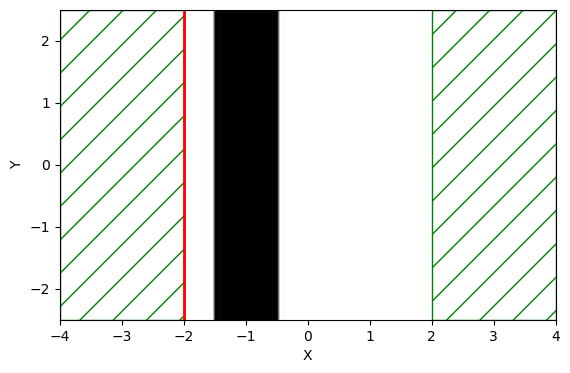

In [4]:
%matplotlib inline
plt.figure(dpi=100)
sim.plot2D()
plt.show()

To know how many energy of wave penetrated sub and atom we should implement class add_flux

     block, center = (-1,0,2)
          size (1,1e+20,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)


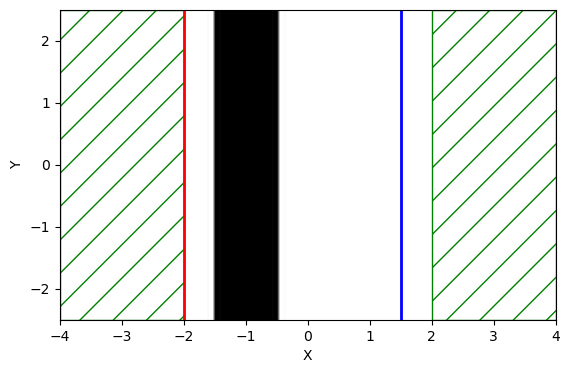

In [5]:
flux_obj = sim.add_flux(
    conf.inc_fcen, 0, 1, mp.FluxRegion(
        center=mp.Vector3(x=conf.flux_center[0]), 
        size=mp.Vector3(y=conf.cell_Y)
    )
)
plt.figure(dpi=100)
sim.plot2D()
plt.show()

In [6]:
sim.run(until=conf.steps) # run 1st part of simulation
input_flux = mp.get_fluxes(flux_obj) # saving flux from sub in input_flux
sim.reset_meep() # purge all adjustments of simulation

-----------
Initializing structure...
Halving computational cell along direction y
time for choose_chunkdivision = 0.00117683 s
Working in 2D dimensions.
Computational cell is 8 x 5 x 0 with resolution 20
     block, center = (-1,0,2)
          size (1,1e+20,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
time for set_epsilon = 0.00773501 s
-----------


FloatProgress(value=0.0, description='0% done ', max=50.0)

run 0 finished at t = 50.0 (2000 timesteps)


Finally, we add meta-atom's geometry

     block, center = (-1,0,2)
          size (1,1e+20,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0,0)
          size (2,4,3)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)


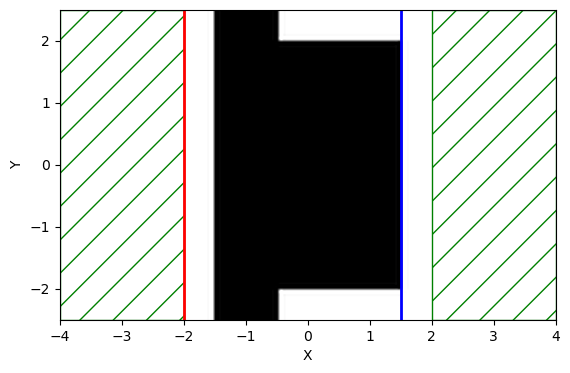

In [7]:
geometry.append(
    mp.Block(
        material=conf.at_material,
        size=mp.Vector3(x=conf.at_hei, y=conf.at_W, z=conf.at_H),
        center=conf.at_center,
    )
)
sim = mp.Simulation(
    cell_size=cell,
    boundary_layers=pml_layers,
    geometry=geometry,
    sources=sources,
    resolution=conf.resolution,
)

flux_obj = sim.add_flux(
    conf.inc_fcen, 0, 1, mp.FluxRegion(
        center=mp.Vector3(x=conf.flux_center[0]), 
        size=mp.Vector3(y=conf.cell_Y)
    )
)
plt.figure(dpi=100)
sim.plot2D()
plt.show()

In [8]:
sim.run(until=conf.steps)
out_flux = mp.get_fluxes(flux_obj) # saving flux from sub in input_flux
print(out_flux)
res = sim.get_eigenmode_coefficients(
    flux_obj, [1], eig_parity=mp.ODD_Z + mp.EVEN_Y
)
coeffs = res.alpha

mode_tran = abs(coeffs[0, 0, 0]) ** 2 / input_flux[0]
mode_phase = np.angle(coeffs[0, 0, 0])
if mode_phase > 0:
    mode_phase -= 2 * np.pi

-----------
Initializing structure...
time for choose_chunkdivision = 3.31402e-05 s
Working in 2D dimensions.
Computational cell is 8 x 5 x 0 with resolution 20
     block, center = (-1,0,2)
          size (1,1e+20,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0,0)
          size (2,4,3)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
time for set_epsilon = 0.014672 s
-----------


FloatProgress(value=0.0, description='0% done ', max=50.0)

run 0 finished at t = 50.0 (2000 timesteps)
[10.505099456604128]
MPB solved for frequency_1(1.2,0,0) = 0.984057 after 22 iters
MPB solved for frequency_1(1.21959,0,0) = 1 after 11 iters
MPB solved for frequency_1(1.21959,0,0) = 1 after 1 iters
Dominant planewave for band 1: (1.219590,-0.000000,0.000000)


We get the base data to collect them into data-set: phase and transmission.
Time to visualise results. Call matlab plot showing Ez field 

     block, center = (-1,0,2)
          size (1,1e+20,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0,0)
          size (2,4,3)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)


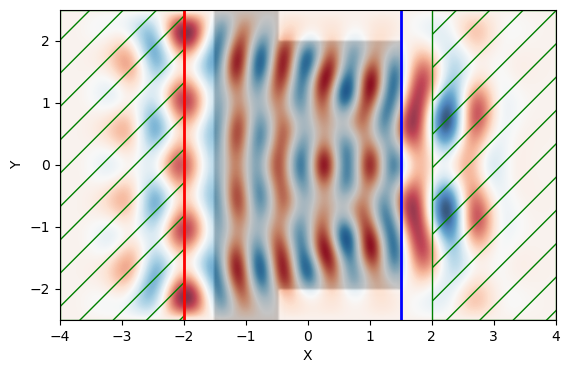

In [9]:
plt.figure(dpi=100)
sim.plot2D(fields=mp.Ez)
plt.show()

In [10]:
print(mode_tran)
print(mode_phase)

0.653881673410078
-1.5947156534726514


In [11]:
sim.reset_meep()
f = plt.figure(dpi=100)
Animate = mp.Animate2D(fields=mp.Ez, f=f, realtime=False, normalize=True)
plt.close()

In [12]:
sim.run(mp.at_every(1, Animate), until=100)
plt.close()

-----------
Initializing structure...
time for choose_chunkdivision = 3.40939e-05 s
Working in 2D dimensions.
Computational cell is 8 x 5 x 0 with resolution 20
     block, center = (-1,0,2)
          size (1,1e+20,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0,0)
          size (2,4,3)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
time for set_epsilon = 0.015089 s
-----------


FloatProgress(value=0.0, description='0% done ')

     block, center = (-1,0,2)
          size (1,1e+20,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
     block, center = (0.5,0,0)
          size (2,4,3)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (2,2,2)
Normalizing field data...
run 1 finished at t = 100.0 (4000 timesteps)


In [13]:
filename = "straight_waveguide.mp4"
Animate.to_mp4(10, filename)

Generating MP4...
